# Paper Reproduction Notebook

This notebook reproduces all figures and tables from the paper using precomputed artifacts.
No API key or external access is required — it reads only precomputed CSV files.

**To reproduce:** Run all cells in order. See `REPRODUCING_RESULTS.md` for full details.

In [1]:
import pandas as pd
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt
import re
from pathlib import Path

## Setup

Paths to precomputed artifacts and metric computation functions.

In [2]:
# Setup: leakage-free artifact sources.
#
# The leaky per-fold-pooled `precomputed/*/ablation_results/nested_cv_*.csv`
# files (the superseded, leaky RRF operating point) have been REMOVED from this release. The RRF numbers
# below are read from the leakage-free, phantom-free harness outputs under
# `baselines/leakage_free_ablation/` (headline RRF F0.5 = 0.102). See that
# directory's full_leakfree.py and results_full_leakfree.json.
import json

# `baselines/` sits at the release root, two levels up from notebooks/.
LEAKFREE_DIR = Path("../../baselines/leakage_free_ablation")

with open(LEAKFREE_DIR / "results_full_leakfree.json") as _fh:
    _leakfree = json.load(_fh)
# Index the panel a/b/c ablation cells by (panel, label).
leakfree_cells = {(c["panel"], c["label"]): c for c in _leakfree["cells"]}

with open(LEAKFREE_DIR / "results_model_panel.json") as _fh:
    model_panel = json.load(_fh)

# Display labels for the question-generating-model panel (match paper figure).
MODEL_DISPLAY = {
    "gpt_4o_mini": "GPT-4o-mini",
    "claude_sonnet_4_5": "Claude\nSonnet 4.5",
    "gpt_5_2": "GPT-5.2",
}

print("Loaded leakage-free ablation cells:", len(leakfree_cells))
print("Loaded model-panel entries:", len(model_panel))


Loaded leakage-free ablation cells: 8
Loaded model-panel entries: 4


## Optimisation Target Comparison

Table comparing F0.5, F1, F2, and Precision optimisation targets.

In [3]:
# Optimisation Target Comparison (F0.5 / F1 / F2 / Precision-optimised RRF)
#
# The alt-objective (F1 / F2 / Precision-optimised) operating points were
# produced only by the leaky per-fold-pooled nested_cv_* harness, which has
# been removed from this leakage-free release. No leakage-free re-run of the
# alt-objective sweep is shipped, so this comparison table is not reproduced
# here. The F0.5-optimised operating point is the headline RRF row
# (F0.5 = 0.102) in "Main Results" below.
print("Optimisation Target Comparison (F1/F2/Precision-optimised variants): "
      "requires the alt-objective nested-CV artifacts, which are not part of "
      "the leakage-free release. See the paper (extended version).")


Optimisation Target Comparison (F1/F2/Precision-optimised variants): requires the alt-objective nested-CV artifacts, which are not part of the leakage-free release. See the paper (extended version).


## Main Results: RRF vs Baselines

Comparison of RRF, elastic net, and vanilla LLM prompting (zero-shot and few-shot).

In [4]:
# --- Load vanilla results with precomputed metrics ---
vanilla_dir = Path("../precomputed/gpt_4o_mini/vanilla")

vanilla_files = {
    "Zero-shot GPT-4o": "vanilla_zero_shot_gpt_4o_mini_anonymised_rep_1.csv",
    "Zero-shot o3": "vanilla_zero_shot_o3_anonymised_rep_1.csv",
    "Zero-shot o3-mini": "vanilla_zero_shot_o3_mini_anonymised_rep_1.csv",
    "Few-shot GPT-4o": "vanilla_few_shot_gpt_4o_mini_anonymised_rep_1.csv",
    "Few-shot o3": "vanilla_few_shot_o3_anonymised_rep_1.csv",
    "Few-shot o3-mini": "vanilla_few_shot_o3_mini_anonymised_rep_1.csv",
}

vanilla_metrics = {}
for label, fname in vanilla_files.items():
    df = pd.read_csv(vanilla_dir / fname)
    if all(c in df.columns for c in ["Prec", "Rec", "F0.5"]):
        vanilla_metrics[label] = {
            "Precision": round(df["Prec"].iloc[3], 3),
            "Recall": round(df["Rec"].iloc[3], 3),
            "F0.5": round(df["F0.5"].iloc[3], 3),
        }

# --- RRF: leakage-free LLM-Only operating point (panel a) ---
# (Leaky nested_cv_* CSV removed from this release; read the leakage-free,
#  phantom-free harness output instead. Values are mean / SD across repeats.)
_rrf = leakfree_cells[("a", "LLM-Only")]
rrf_row = {
    "Precision": _rrf["precision"],
    "Recall": _rrf["recall"],
    "F0.5": _rrf["f05"],
    "Precision_SD": _rrf["precision_sd"],
    "Recall_SD": _rrf["recall_sd"],
    "F0.5_SD": _rrf["f05_sd"],
}

# --- LogReg: compute per-repeat metrics for mean ± SD ---
logreg_bench_path = Path("../precomputed/gpt_4o_mini/benchmark_results/benchmark_gpt_4o_mini.csv")
logreg_bench = pd.read_csv(logreg_bench_path)
en_rows = logreg_bench[logreg_bench["Model"] == "ElasticNet LogReg"]

lr_repeat_metrics = {"Precision": [], "Recall": [], "F0.5": []}
for _, g in en_rows.groupby("Repeat"):
    lr_repeat_metrics["Precision"].append(g["Test Prec"].mean())
    lr_repeat_metrics["Recall"].append(g["Test Rec"].mean())
    lr_repeat_metrics["F0.5"].append(g["Test F0.5"].mean())

lr_row = {
    "Precision": np.mean(lr_repeat_metrics["Precision"]),
    "Recall": np.mean(lr_repeat_metrics["Recall"]),
    "F0.5": np.mean(lr_repeat_metrics["F0.5"]),
    "Precision_SD": np.std(lr_repeat_metrics["Precision"], ddof=1),
    "Recall_SD": np.std(lr_repeat_metrics["Recall"], ddof=1),
    "F0.5_SD": np.std(lr_repeat_metrics["F0.5"], ddof=1),
}

# --- Build combined table ---
custom_order = [
    ("RRF", "LLM + Ensemble", rrf_row, True),
    ("LogReg (EN)", "Learned Weights", lr_row, True),
    ("o3", "Few Shot", vanilla_metrics.get("Few-shot o3", {}), False),
    ("GPT-4o-mini", "Zero Shot", vanilla_metrics.get("Zero-shot GPT-4o", {}), False),
    ("o3-mini", "Zero Shot", vanilla_metrics.get("Zero-shot o3-mini", {}), False),
    ("GPT-4o-mini", "Few Shot", vanilla_metrics.get("Few-shot GPT-4o", {}), False),
    ("o3", "Zero Shot", vanilla_metrics.get("Zero-shot o3", {}), False),
    ("o3-mini", "Few Shot", vanilla_metrics.get("Few-shot o3-mini", {}), False),
]

# Sort by F0.5 descending
custom_order.sort(key=lambda x: x[2].get("F0.5", 0), reverse=True)

# Find max values for bolding
all_prec = [r[2]["Precision"] for r in custom_order]
all_rec = [r[2]["Recall"] for r in custom_order]
all_f05 = [r[2]["F0.5"] for r in custom_order]
max_prec, max_rec, max_f05 = max(all_prec), max(all_rec), max(all_f05)

# Format table
rows = []
for model, approach, metrics, has_sd in custom_order:
    row = {"Model": model, "Approach": approach}
    for col in ["Precision", "Recall", "F0.5"]:
        val = metrics[col]
        is_max = (col == "Precision" and val == max_prec) or \
                 (col == "Recall" and val == max_rec) or \
                 (col == "F0.5" and val == max_f05)
        if has_sd:
            sd = metrics[f"{col}_SD"]
            text = f"{val:.3f} ± {sd:.3f}"
        else:
            text = f"{val:.3f}"
        if is_max:
            text = f"**{text}**"
        row[col] = text
    rows.append(row)

styled_table = pd.DataFrame(rows)

print("\n📊 Final Table (Markdown-style for LaTeX):\n")
print(styled_table.to_markdown(index=False))

# Also print raw values for easy LaTeX copy-paste
print("\n\nRaw values:")
print(f"RRF:    Prec={rrf_row['Precision']:.3f}±{rrf_row['Precision_SD']:.3f}, "
      f"Rec={rrf_row['Recall']:.3f}±{rrf_row['Recall_SD']:.3f}, "
      f"F0.5={rrf_row['F0.5']:.3f}±{rrf_row['F0.5_SD']:.3f}")
print(f"LogReg: Prec={lr_row['Precision']:.3f}±{lr_row['Precision_SD']:.3f}, "
      f"Rec={lr_row['Recall']:.3f}±{lr_row['Recall_SD']:.3f}, "
      f"F0.5={lr_row['F0.5']:.3f}±{lr_row['F0.5_SD']:.3f}")


📊 Final Table (Markdown-style for LaTeX):

| Model       | Approach        | Precision         | Recall        | F0.5              |
|:------------|:----------------|:------------------|:--------------|:------------------|
| RRF         | LLM + Ensemble  | **0.109 ± 0.016** | 0.082 ± 0.014 | **0.102 ± 0.015** |
| o3          | Few Shot        | 0.077             | 0.196         | 0.088             |
| GPT-4o-mini | Zero Shot       | 0.079             | 0.139         | 0.086             |
| o3-mini     | Zero Shot       | 0.070             | 0.177         | 0.080             |
| LogReg (EN) | Learned Weights | 0.089 ± 0.022     | 0.077 ± 0.018 | 0.080 ± 0.016     |
| GPT-4o-mini | Few Shot        | 0.065             | **0.316**     | 0.077             |
| o3          | Zero Shot       | 0.083             | 0.036         | 0.066             |
| o3-mini     | Few Shot        | 0.038             | 0.286         | 0.047             |


Raw values:
RRF:    Prec=0.109±0.016, Rec=0.082±0.014,

In [5]:
# --- Question source data (for combined figure panel a) ---
# Leakage-free panel-a operating points (LLM-Only / LLM+Expert / Expert-Only).
def _panel_a(label):
    c = leakfree_cells[("a", label)]
    return {"Precision": c["precision"], "Recall": c["recall"], "F0.5": c["f05"]}

llm_metrics = _panel_a("LLM-Only")
llm_exp_metrics = _panel_a("LLM+Expert")
exp_metrics = _panel_a("Expert-Only")


## Question-Generating Model Comparison

Comparison across three question-generating LLMs: GPT-4o-mini, Claude Sonnet 4.5, and GPT-5.2.
Each model's questions were scored by GPT-4o-mini on the same test set.

In [6]:
# === Question-Generating Model Comparison ===
# Leakage-free, phantom-free per-model operating points
# (baselines/leakage_free_ablation/results_model_panel.json).
# RRF F0.5 vs Elastic-Net (LogReg) F0.5, best hamming threshold per model.
#
# Per-model precision/recall are only available leakage-free for the primary
# model (GPT-4o-mini, panel a); the model panel itself carries F0.5 only.
_pr = leakfree_cells[("a", "LLM-Only")]
model_ablation_scores = {}
logreg_scores = {}
for _key, _disp in MODEL_DISPLAY.items():
    _m = model_panel[_key]
    _prec = _pr["precision"] if _key == "gpt_4o_mini" else None
    _rec = _pr["recall"] if _key == "gpt_4o_mini" else None
    model_ablation_scores[_disp] = {"Precision": _prec, "Recall": _rec, "F0.5": _m["rrf_f05"]}
    logreg_scores[_disp] = _m["en_f05"]

print("\n📊 Question-Generating Model Comparison (RRF, best threshold per model):\n")
print(f"{'Model':<25} {'Prec':>8} {'Rec':>8} {'F0.5':>8} {'LogReg F0.5':>12}")
print("-" * 60)
for _disp, _scores in model_ablation_scores.items():
    _clean = _disp.replace('\n', ' ')
    _p = f"{_scores['Precision']:.4f}" if _scores['Precision'] is not None else "—"
    _r = f"{_scores['Recall']:.4f}" if _scores['Recall'] is not None else "—"
    _lr = logreg_scores.get(_disp)
    _lr_str = f"{_lr:.4f}" if _lr is not None else "—"
    print(f"{_clean:<25} {_p:>8} {_r:>8} {_scores['F0.5']:8.4f} {_lr_str:>12}")



📊 Question-Generating Model Comparison (RRF, best threshold per model):

Model                         Prec      Rec     F0.5  LogReg F0.5
------------------------------------------------------------
GPT-4o-mini                 0.1088   0.0816   0.1019       0.0795
Gemini 2.5 Pro                   —        —   0.0808       0.0613
Claude Sonnet 4.5                —        —   0.0830       0.0606
GPT-5.2                          —        —   0.0638       0.0415


In [7]:
# === Question-Generating Model Comparison: data gathering (for figure) ===
rrf_scores = {_disp: model_panel[_key]["rrf_f05"] for _key, _disp in MODEL_DISPLAY.items()}
lr_scores = {_disp: model_panel[_key]["en_f05"] for _key, _disp in MODEL_DISPLAY.items()}

# Order by RRF score descending
model_order = sorted(rrf_scores.keys(), key=lambda x: rrf_scores[x], reverse=True)

print("Data summary:")
print(f"{'Model':<25} {'RRF F0.5':>10} {'LogReg F0.5':>12} {'Winner':>8}")
print("-" * 58)
for m in model_order:
    clean = m.replace('\n', ' ')
    rrf = rrf_scores[m]
    lr = lr_scores.get(m, 0)
    winner = "RRF" if rrf >= lr else "LogReg"
    print(f"{clean:<25} {rrf:10.3f} {lr:12.3f} {winner:>8}")


Data summary:
Model                       RRF F0.5  LogReg F0.5   Winner
----------------------------------------------------------
GPT-4o-mini                    0.102        0.080      RRF
Claude Sonnet 4.5              0.083        0.061      RRF
Gemini 2.5 Pro                 0.081        0.061      RRF
GPT-5.2                        0.064        0.041      RRF


## Combined Ablation Figure

Five-panel figure covering: question source, question-generating model, similarity metric, Hamming threshold, and evaluation strategy.

/var/folders/ns/tslg8ntj4w738dcvw_9b255w0000gq/T/ipykernel_57339/2120061478.py:229: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


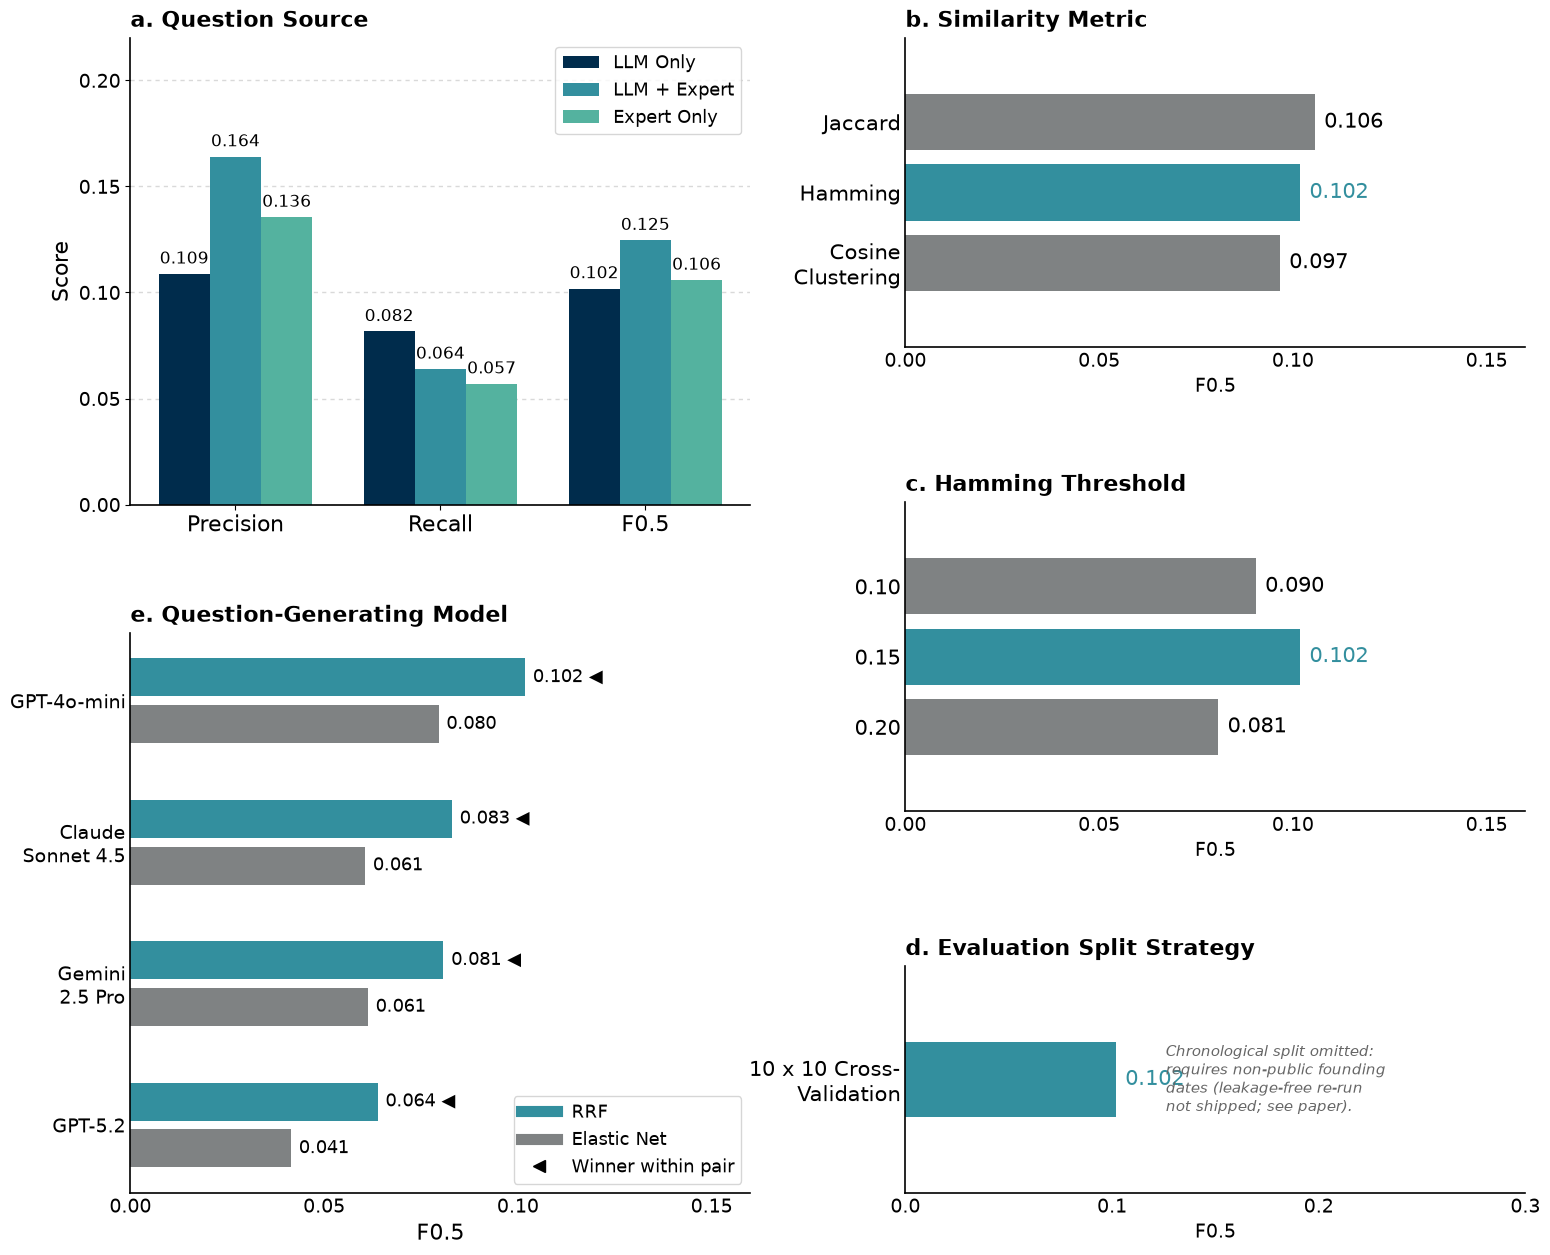

In [8]:
# =====================================================================
# Combined Figure: all main panels in one layout
# Top-left (a): Question Source (LLM Only / LLM+Expert / Expert Only)
# Bottom-left (e): Question-Generating Model (RRF vs Elastic Net)
# Right column (b-d): Ablation panels
# =====================================================================
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D

# --- Leakage-free F0.5 for panels b-d (baselines/leakage_free_ablation) ---
pooled_means = {
    "LLM-Only\nhamming, sim=0.15; optimise=f0.5; sortby=f0.5": leakfree_cells[("b", "hamming 0.15")]["f05"],
    "LLM-Only\njaccard, sim=0.9; optimise=f0.5; sortby=f0.5": leakfree_cells[("b", "jaccard 0.90")]["f05"],
    "LLM-Only\ncosine-cluster, sim=0.85; optimise=f0.5; sortby=f0.5": leakfree_cells[("b", "cosine 0.85")]["f05"],
    "LLM-Only\nhamming, sim=0.1; optimise=f0.5; sortby=f0.5": leakfree_cells[("c", "hamming 0.10")]["f05"],
    "LLM-Only\nhamming, sim=0.2; optimise=f0.5; sortby=f0.5": leakfree_cells[("c", "hamming 0.20")]["f05"],
}

# CV vs chronological (panel d): the chronological split needs non-public
# founding dates and has no leakage-free re-run shipped, so only the
# leakage-free cross-validation operating point is drawn (see the panel note).
score_cv = leakfree_cells[("b", "hamming 0.15")]["f05"]

# --- Build figure ---
fig = plt.figure(figsize=(18, 15))

# Layout: 2 cols; left split into 2 rows, right split into 3 rows
gs_outer = GridSpec(1, 2, figure=fig, width_ratios=[1, 1], wspace=0.25)

# Left column: top (a) and bottom (e)
gs_left = gs_outer[0].subgridspec(2, 1, height_ratios=[1, 1.2], hspace=0.25)

# Right column: 3 ablation panels (b, c, d)
gs_right = gs_outer[1].subgridspec(3, 1, height_ratios=[3, 3, 2.2], hspace=0.55)

# === Shared style settings ===
highlight_color = "#338f9e"
default_color = "#7f8283"
bar_colors_3 = ["#002c4c", "#338f9e", "#54b29f"]
rrf_color = "#338f9e"
lr_color = "#7f8283"

# =====================================================================
# Panel (a): Question Source — grouped vertical bar chart
# =====================================================================
ax_a = fig.add_subplot(gs_left[0])

metric_names = ["Precision", "Recall", "F0.5"]
x = np.arange(len(metric_names))
width = 0.25

llm_vals = [llm_metrics["Precision"], llm_metrics["Recall"], llm_metrics["F0.5"]]
llm_exp_vals = [llm_exp_metrics["Precision"], llm_exp_metrics["Recall"], llm_exp_metrics["F0.5"]]
exp_vals = [exp_metrics["Precision"], exp_metrics["Recall"], exp_metrics["F0.5"]]

bars1 = ax_a.bar(x - width, llm_vals, width, label="LLM Only", color=bar_colors_3[0])
bars2 = ax_a.bar(x, llm_exp_vals, width, label="LLM + Expert", color=bar_colors_3[1])
bars3 = ax_a.bar(x + width, exp_vals, width, label="Expert Only", color=bar_colors_3[2])

for bar_group in [bars1, bars2, bars3]:
    for bar in bar_group:
        height = bar.get_height()
        ax_a.text(bar.get_x() + bar.get_width()/2, height + 0.003,
                  f"{height:.3f}", ha='center', va='bottom', fontsize=12)

ax_a.set_ylabel("Score", fontsize=16)
ax_a.set_xticks(x)
ax_a.set_xticklabels(metric_names, fontsize=16)
ax_a.set_yticks([0.0, 0.05, 0.1, 0.15, 0.20])
ax_a.set_ylim(0, 0.22)
ax_a.tick_params(axis='y', labelsize=14)
ax_a.legend(fontsize=13, loc="upper right")
ax_a.set_title("a. Question Source", loc="left", fontweight="bold", fontsize=16, pad=8)

ax_a.grid(False)
ax_a.set_axisbelow(True)
ax_a.yaxis.grid(True, linestyle=(0, (3, 3)), linewidth=1.0, color="0.85")
for s in ['top', 'right']:
    ax_a.spines[s].set_visible(False)
for s in ['bottom', 'left']:
    ax_a.spines[s].set_visible(True)
    ax_a.spines[s].set_color("black")
    ax_a.spines[s].set_linewidth(1.2)

# =====================================================================
# Panel (e): Question-Generating Model — RRF vs Elastic Net
# =====================================================================
ax_e = fig.add_subplot(gs_left[1])

bar_h = 0.35
group_gap = 1.3
pair_gap = 0.04

y_pos_rrf, y_pos_lr, rrf_vals, lr_vals = [], [], [], []
for i, m in enumerate(model_order):
    center = i * group_gap
    y_pos_rrf.append(center - bar_h/2 - pair_gap)
    y_pos_lr.append(center + bar_h/2 + pair_gap)
    rrf_vals.append(rrf_scores[m])
    lr_vals.append(lr_scores.get(m, 0))

y_pos_rrf = np.array(y_pos_rrf)
y_pos_lr = np.array(y_pos_lr)

bars_rrf = ax_e.barh(y_pos_rrf, rrf_vals, height=bar_h, color=rrf_color)
bars_lr = ax_e.barh(y_pos_lr, lr_vals, height=bar_h, color=lr_color)

for bar, val, lr_val in zip(bars_rrf, rrf_vals, lr_vals):
    marker = " \u25c0" if val >= lr_val else ""
    ax_e.text(val + 0.002, bar.get_y() + bar.get_height()/2,
              f"{val:.3f}{marker}", va="center", ha="left", fontsize=13)

for bar, val, rrf_val in zip(bars_lr, lr_vals, rrf_vals):
    marker = " \u25c0" if val > rrf_val else ""
    ax_e.text(val + 0.002, bar.get_y() + bar.get_height()/2,
              f"{val:.3f}{marker}", va="center", ha="left", fontsize=13)

centers = [i * group_gap for i in range(len(model_order))]
ax_e.set_yticks(centers)
ax_e.set_yticklabels([m for m in model_order], fontsize=14)
ax_e.invert_yaxis()
ax_e.set_xlim(0, 0.16)
ax_e.set_xticks([0.00, 0.05, 0.10, 0.15])
ax_e.set_xlabel("F0.5", fontsize=16)
ax_e.set_title("e. Question-Generating Model", loc="left", fontweight="bold", fontsize=16, pad=8)

legend_e = [
    Line2D([0], [0], color=rrf_color, lw=8, label="RRF"),
    Line2D([0], [0], color=lr_color, lw=8, label="Elastic Net"),
    Line2D([0], [0], marker="<", color="black", linestyle="None",
           markersize=8, label="Winner within pair"),
]
ax_e.legend(handles=legend_e, fontsize=13, loc="lower right")

for s in ["top", "right"]:
    ax_e.spines[s].set_visible(False)
for s in ["left", "bottom"]:
    ax_e.spines[s].set_visible(True)
    ax_e.spines[s].set_color("black")
    ax_e.spines[s].set_linewidth(1.2)
ax_e.grid(False)
ax_e.tick_params(axis="both", length=0)
ax_e.tick_params(axis="x", labelsize=14)

# =====================================================================
# Right column: Ablation panels (b, c, d)
# =====================================================================
highlight_label = "LLM-Only\nhamming, sim=0.15; optimise=f0.5; sortby=f0.5"

groups = [
    ("b. Similarity Metric", [
        ("LLM-Only\nhamming, sim=0.15; optimise=f0.5; sortby=f0.5", "Hamming"),
        ("LLM-Only\njaccard, sim=0.9; optimise=f0.5; sortby=f0.5", "Jaccard"),
        ("LLM-Only\ncosine-cluster, sim=0.85; optimise=f0.5; sortby=f0.5", "Cosine\nClustering"),
    ], True, 1.0),
    ("c. Hamming Threshold", [
        ("LLM-Only\nhamming, sim=0.1; optimise=f0.5; sortby=f0.5", "0.10"),
        ("LLM-Only\nhamming, sim=0.15; optimise=f0.5; sortby=f0.5", "0.15"),
        ("LLM-Only\nhamming, sim=0.2; optimise=f0.5; sortby=f0.5", "0.20"),
    ], False, 1.0),
    ("d. Evaluation Split Strategy", [
        ("__cv__", "10 x 10 Cross-\nValidation"),
    ], False, 1.0),
]

pooled_means_combined = dict(pooled_means)
pooled_means_combined["__cv__"] = score_cv

xlim_default = (0, 0.16)
xticks_default = (0.00, 0.05, 0.10, 0.15)
xlim_chron = (0, 0.30)
xticks_chron = (0.00, 0.10, 0.20, 0.30)

bar_h_abl = 0.8
gap_abl = 0.8

for idx, (title, label_pairs, do_sort, row_gap) in enumerate(groups):
    ax = fig.add_subplot(gs_right[idx])
    is_chron = title.startswith("d.")
    xlim = xlim_chron if is_chron else xlim_default
    xticks = xticks_chron if is_chron else xticks_default

    if do_sort:
        label_pairs = sorted(label_pairs, key=lambda x: pooled_means_combined.get(x[0], 0), reverse=True)

    raw_labels = [r for r, _ in label_pairs]
    disp_labels = [d for _, d in label_pairs]
    means = [pooled_means_combined.get(r, 0) for r in raw_labels]

    if is_chron:
        colors = [highlight_color if r == "__cv__" else default_color for r in raw_labels]
    else:
        colors = [highlight_color if r == highlight_label else default_color for r in raw_labels]

    y = np.arange(len(disp_labels)) * row_gap
    bars = ax.barh(y, means, height=bar_h_abl, color=colors)

    ax.set_yticks(y)
    ax.set_yticklabels(disp_labels, fontsize=15)
    ax.invert_yaxis()
    ax.set_ylim(y[-1] + gap_abl + bar_h_abl/2, -gap_abl - bar_h_abl/2)
    ax.set_xlim(*xlim)
    ax.set_xticks(list(xticks))
    ax.set_xlabel("F0.5", fontsize=14)
    ax.set_title(title, loc="left", fontweight="bold", fontsize=16, pad=8)
    ax.tick_params(axis="x", labelsize=14)

    for bar, score, raw in zip(bars, means, raw_labels):
        if is_chron:
            txt_col = highlight_color if raw == "__cv__" else "black"
        else:
            txt_col = highlight_color if raw == highlight_label else "black"
        ax.text(bar.get_width() + (xlim[1] * 0.015), bar.get_y() + bar.get_height()/2,
                f"{score:.3f}", va="center", ha="left", fontsize=15, color=txt_col)

    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_visible(True)
        ax.spines[s].set_color("black")
        ax.spines[s].set_linewidth(1.2)
    if is_chron:
        ax.text(xlim[1] * 0.42, 0.0,
                "Chronological split omitted:\nrequires non-public founding\ndates (leakage-free re-run\nnot shipped; see paper).",
                fontsize=11, style="italic", color="0.4", va="center", ha="left")
    ax.grid(False)
    ax.tick_params(axis="both", length=0)

plt.tight_layout()
plt.show()

## Optimisation Target Ablation (Detailed)

Detailed metrics table for the optimisation target ablation (pooled across repeats).

In [9]:
# Optimisation Target Ablation (Detailed): F0.5 / F1 / F2 / Precision-optimised
#
# The alt-objective (F1 / F2 / Precision-optimised) RRF operating points were
# produced only by the leaky per-fold-pooled nested_cv_* harness, which has
# been removed from this leakage-free release. No leakage-free re-run of the
# alt-objective sweep is shipped, so this detailed table is not reproduced
# here. The F0.5-optimised operating point is the headline RRF row
# (P / R / F0.5 = 0.109 / 0.082 / 0.102) in "Main Results" above.
print("Optimisation Target Ablation (Detailed): requires the alt-objective "
      "nested-CV artifacts, which are not part of the leakage-free release. "
      "See the paper (extended version).")


Optimisation Target Ablation (Detailed): requires the alt-objective nested-CV artifacts, which are not part of the leakage-free release. See the paper (extended version).


## Hyperparameter Sensitivity

Two-panel figure: (a) rank vs F0.5 convergence across the hyperparameter grid, and (b) stability of selected hyperparameters across cross-validation folds.

In [10]:
# Hyperparameter Sensitivity (2-panel figure)
#
# Panel (a) rank-vs-F0.5 landscape read the coarse grid-search artifact
# (grid_search_results_anonymised.csv), whose F0.5 values were computed with
# the pre-correction (leaky) protocol; panel (b) fold-stability scatter read
# the per-fold nested_cv_* artifact, which has been removed from this release.
# Neither panel has a leakage-free source shipped, so this sensitivity figure
# is not reproduced here.
print("Hyperparameter Sensitivity figure: leakage-free per-fold and "
      "grid-search artifacts are not part of this release; figure omitted. "
      "See the paper (extended version).")


Hyperparameter Sensitivity figure: leakage-free per-fold and grid-search artifacts are not part of this release; figure omitted. See the paper (extended version).


## Full Table 2 and Figures 4-5

This notebook covers the founder Rule Forest headline, the prompting rows, the generator
comparison, and the ablation figure. The remaining paper artifacts are produced by scripts
(see `REPRODUCING_RESULTS.md`):

- Engineered ML / Embeddings: `baselines/traditional_ml_port/results/test_set_protocol_b_summary.csv`
- GPTree / RRM (Table 2): `python baselines_llm/rescore/rescore_gptree_rrm.py`
- Figure 4 (founder count-effect) and Figure 5 (Kiva): `python count_effect/make_figure4.py` and `make_figure5.py`
